# Customer-Support Dataset: EDA and Data Cleaning

This notebook explores and cleans the Bitext customer-support dataset for an intent-classification project. It checks structure, missing and duplicate values, conflicting labels, entity placeholders, class distributions, and text lengths. It then creates and saves a clean modeling dataset.


## 1. Setup and data loading

In [38]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from datasets import load_dataset

sns.set_theme(style="whitegrid")

dataset = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
)
df_raw = pd.DataFrame(dataset["train"].to_dict())
df_raw.head()

,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


## 2. Dataset overview

Inspect the dimensions and number of target classes before cleaning.

In [39]:
print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]}")
print(f"Categories: {df_raw['category'].nunique()}")
print(f"Intents: {df_raw['intent'].nunique()}")

Rows: 26,872
Columns: 5
Categories: 11
Intents: 27


## 3. Basic cleaning

Trim whitespace and convert empty strings to missing values. `instruction_model` is the single prepared text column used for quality checks, duplicate removal, and model training. It normalizes entity placeholders and casing, removes punctuation, and collapses repeated whitespace while preserving spelling variation.

In [40]:
df_clean = df_raw.copy()


for column in df_clean.columns:
    df_clean[column] = df_clean[column].str.strip().replace("", pd.NA)

df_clean["category"] = df_clean["category"].str.lower()
df_clean["intent"] = df_clean["intent"].str.lower()

ENTITY_PATTERN = r"\{\{\s*([^{}]+?)\s*\}\}"

def preprocess_instruction(text):
    if pd.isna(text):
        return text

    def replace_entity(match):
        name = re.sub(r"\W+", "_", match.group(1)).strip("_")
        return f"<{name}>"

    text = re.sub(ENTITY_PATTERN, replace_entity, text)
    text = text.casefold()
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_clean["instruction_model"] = (
    df_clean["instruction"].apply(preprocess_instruction)
)

## 4. Missing values, duplicates, and conflicting labels

In [41]:
missing_summary = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_percentage": df_clean.isna().mean().mul(100).round(2),
}).sort_values("missing_count", ascending=False)

display(missing_summary)

,missing_count,missing_percentage
flags,0,0.0
instruction,0,0.0
category,0,0.0
intent,0,0.0
response,0,0.0
instruction_model,0,0.0


In [42]:
duplicate_summary = pd.DataFrame({
    "subset": ["Complete rows", "Instructions", "Responses", "Instruction-response pairs"],
    "duplicate_count": [
        df_clean.duplicated().sum(),
        df_clean["instruction_model"].duplicated().sum(),
        df_clean["response"].duplicated().sum(),
        df_clean[["instruction_model", "response"]].duplicated().sum(),
    ],
})

display(duplicate_summary)

,subset,duplicate_count
0,Complete rows,0
1,Instructions,2598
2,Responses,2
3,Instruction-response pairs,0


In [43]:
# Check conflicts
instruction_labels = df_clean.groupby("instruction_model")["intent"].agg(
    number_of_intents="nunique",
    intents=lambda values: sorted(values.unique()),
)
conflicting_instructions = instruction_labels.query("number_of_intents > 1")

print(f"Instructions assigned to multiple intents: {len(conflicting_instructions):,}")

Instructions assigned to multiple intents: 0


## 5. Entity placeholders

Extract placeholders such as `{{Order Number}}` for analysis. Their normalized forms, such as `<order_number>`, are already stored in `instruction_model`.

In [44]:
df_clean["entities"] = df_clean["instruction"].apply(
    lambda text: re.findall(ENTITY_PATTERN, text) if pd.notna(text) else []
)
entity_counts = (
    df_clean["entities"].explode().dropna().value_counts()
    .rename_axis("entity").reset_index(name="count")
)
df_clean[["instruction", "instruction_model", "entities"]].head()

,instruction,instruction_model,entities
0,question about cancelling order {{Order Number}},question about cancelling order <order_number>,[Order Number]
1,i have a question about cancelling oorder {{Or...,i have a question about cancelling oorder <ord...,[Order Number]
2,i need help cancelling puchase {{Order Number}},i need help cancelling puchase <order_number>,[Order Number]
3,I need to cancel purchase {{Order Number}},i need to cancel purchase <order_number>,[Order Number]
4,"I cannot afford this order, cancel purchase {{...","i cannot afford this order, cancel purchase <o...",[Order Number]


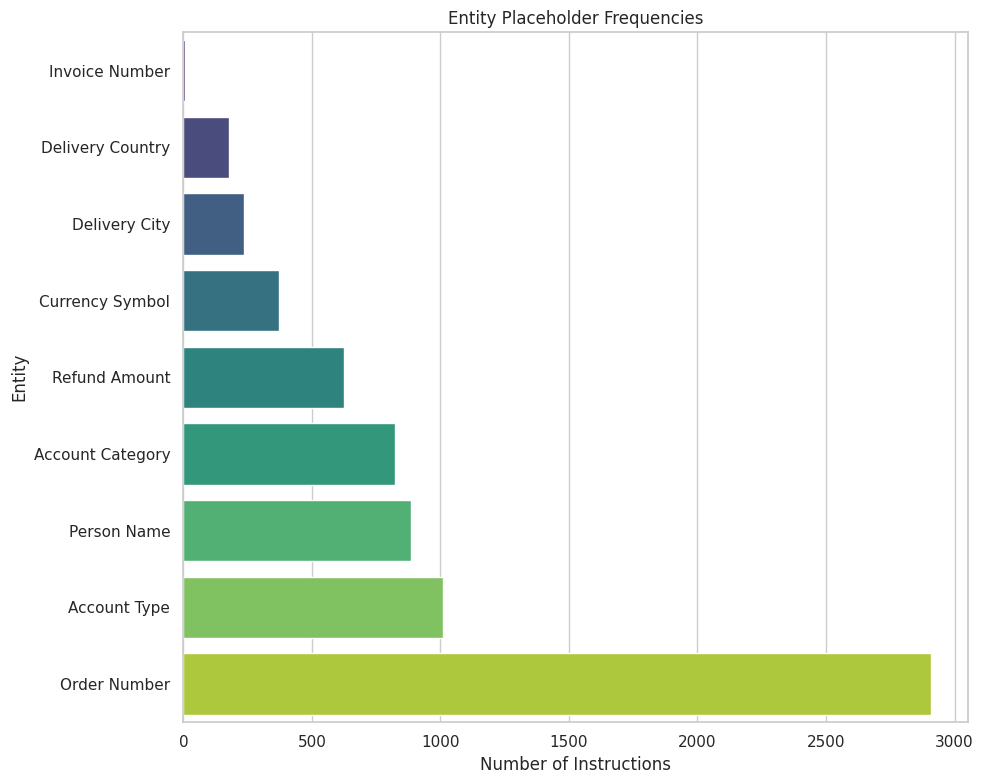

In [51]:
plt.figure(figsize=(10, 8))
sns.barplot(data=entity_counts.sort_values("count"), x="count", y="entity", hue="entity", palette="viridis", legend=False)
plt.title("Entity Placeholder Frequencies")
plt.xlabel("Number of Instructions")
plt.ylabel("Entity")
plt.tight_layout()
plt.show()

## 6. Create the cleaned intent-classification dataset


In [52]:
rows_before = len(df_clean)
intent_df = (
    df_clean[["instruction", "instruction_model", "category", "intent"]]
    .drop_duplicates(subset=["instruction_model"])
    .reset_index(drop=True)
)
print(f"Rows removed: {rows_before - len(intent_df):,}")
print(f"Rows remaining: {len(intent_df):,}")
intent_df.head()

Rows removed: 2,598
Rows remaining: 24,274


,instruction,instruction_model,category,intent
0,question about cancelling order {{Order Number}},question about cancelling order <order_number>,order,cancel_order
1,i have a question about cancelling oorder {{Or...,i have a question about cancelling oorder <ord...,order,cancel_order
2,i need help cancelling puchase {{Order Number}},i need help cancelling puchase <order_number>,order,cancel_order
3,I need to cancel purchase {{Order Number}},i need to cancel purchase <order_number>,order,cancel_order
4,"I cannot afford this order, cancel purchase {{...","i cannot afford this order, cancel purchase <o...",order,cancel_order


## 8. EDA on the cleaned dataset

In [53]:
category_intent_summary = intent_df.groupby("category")["intent"].agg(
    number_of_intents="nunique",
    intents=lambda values: sorted(values.unique()),
).sort_index()
category_intent_summary

,number_of_intents,intents
category,,
account,6,"[create_account, delete_account, edit_account,..."
cancel,1,[check_cancellation_fee]
contact,2,"[contact_customer_service, contact_human_agent]"
delivery,2,"[delivery_options, delivery_period]"
feedback,2,"[complaint, review]"
invoice,2,"[check_invoice, get_invoice]"
order,4,"[cancel_order, change_order, place_order, trac..."
payment,2,"[check_payment_methods, payment_issue]"
refund,3,"[check_refund_policy, get_refund, track_refund]"


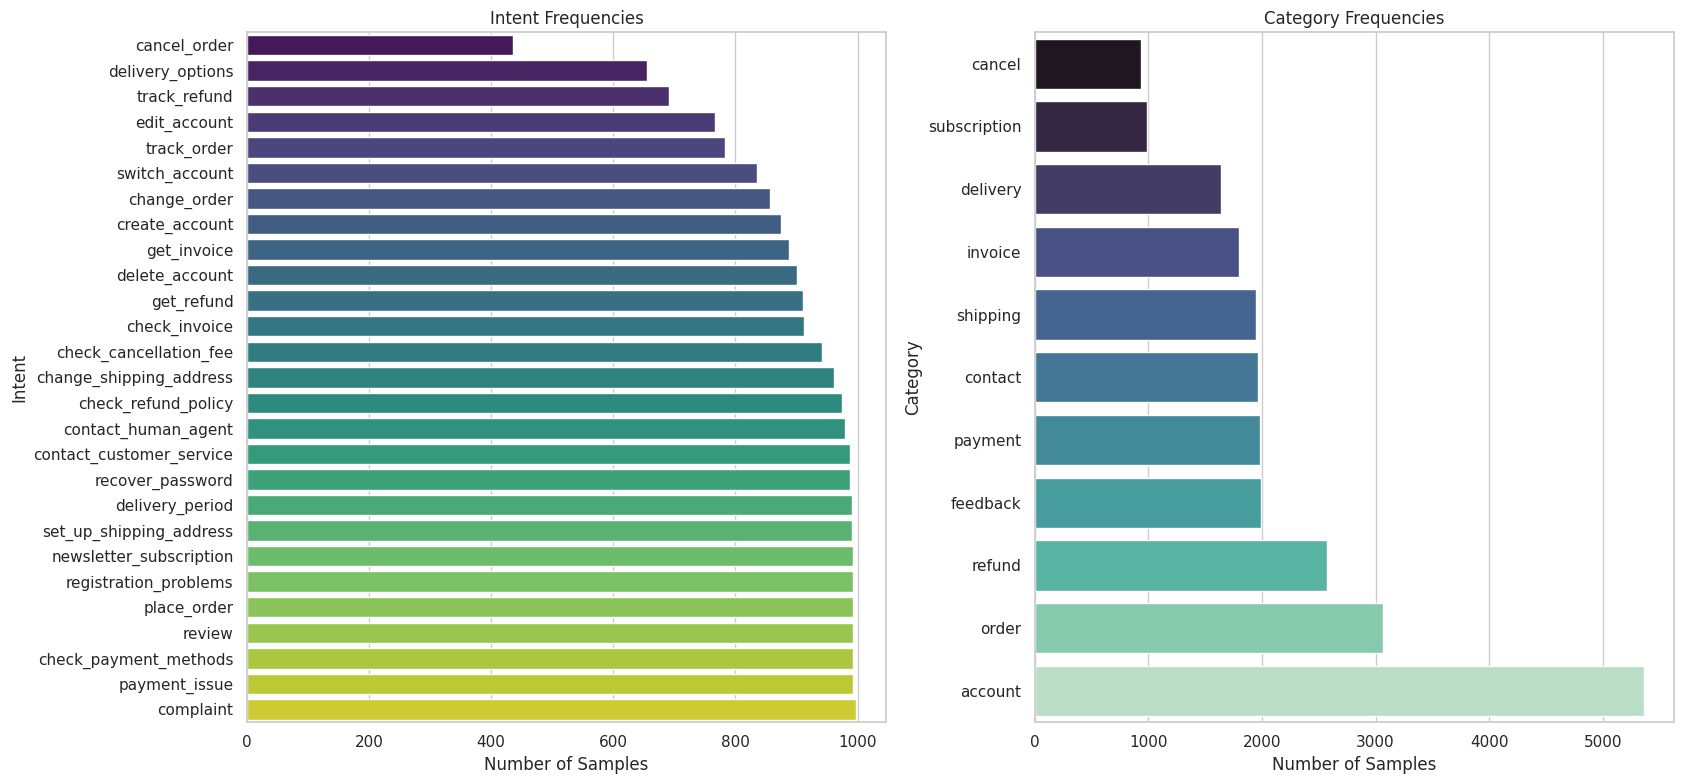

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
intent_counts = intent_df["intent"].value_counts().sort_values()
category_counts = intent_df["category"].value_counts().sort_values()

sns.barplot(x=intent_counts.values, y=intent_counts.index, hue=intent_counts.index, palette="viridis", legend=False, ax=axes[0])
axes[0].set(title="Intent Frequencies", xlabel="Number of Samples", ylabel="Intent")
sns.barplot(x=category_counts.values, y=category_counts.index, hue=category_counts.index, palette="mako", legend=False, ax=axes[1])
axes[1].set(title="Category Frequencies", xlabel="Number of Samples", ylabel="Category")
plt.tight_layout()
plt.show()

In [55]:
intent_df["instruction_word_count"] = intent_df["instruction_model"].str.split().str.len()
df_clean["response_word_count"] = df_clean["response"].str.split().str.len()

length_summary = pd.DataFrame({
    "instruction_word_count": intent_df["instruction_word_count"].describe(),
    "response_word_count": df_clean["response_word_count"].describe(),
}).round(2)
length_summary

,instruction_word_count,response_word_count
count,24274.00,26872.00
mean,8.68,104.79
std,2.57,52.97
min,1.00,9.00
25%,7.00,72.00
50%,9.00,90.00
75%,11.00,124.00
max,16.00,402.00


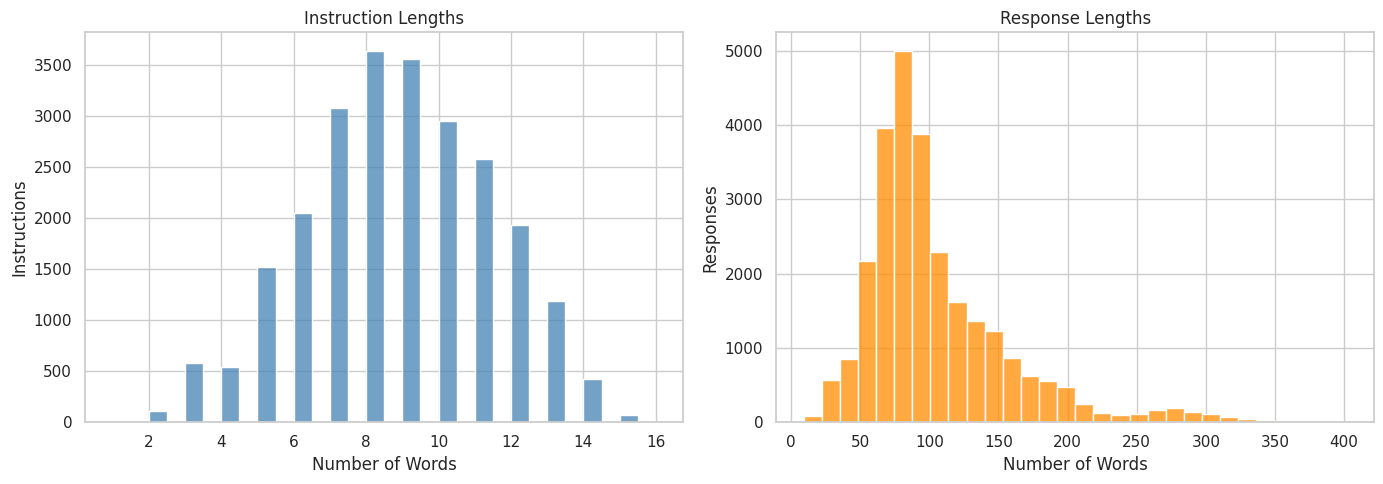

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=intent_df, x="instruction_word_count", bins=30, color="steelblue", ax=axes[0])
axes[0].set(title="Instruction Lengths", xlabel="Number of Words", ylabel="Instructions")
sns.histplot(data=df_clean, x="response_word_count", bins=30, color="darkorange", ax=axes[1])
axes[1].set(title="Response Lengths", xlabel="Number of Words", ylabel="Responses")
plt.tight_layout()
plt.show()

## 9. Save the cleaned dataset

In [61]:
project_root = Path("..")
output_dir = project_root / "data"
output_dir.mkdir(parents=True, exist_ok=True)

model_columns = ["instruction_model", "category", "intent"]
output_path = output_dir / "intent_classification_dataset.csv"
intent_df[model_columns].rename(columns={"instruction_model":"instruction"}).to_csv(output_path, index=False)